# Птичий эфир: отличаем два сигнала

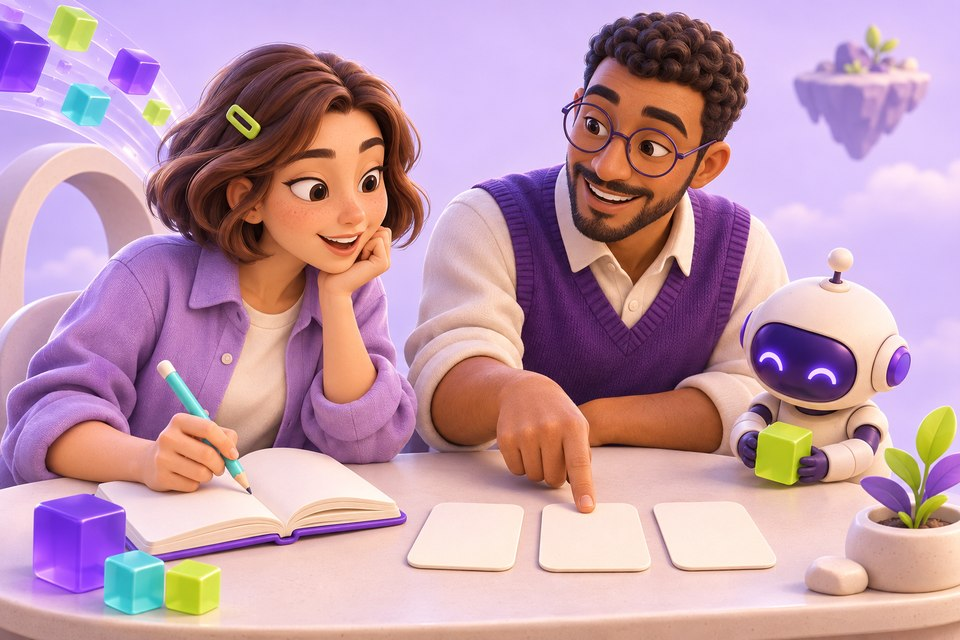

**Соберём признаки звука и проверим их на новых записях.**

**Твой результат:** Разделить записи до нарезки и распознать два искусственных звуковых класса.

**Что разбираем:** Короткий вход в классификацию аудио; исходный эксперимент с 88 видами птиц остаётся в архиве.

**Данные:** Синтетические записи двух тонов с шумом. Это не голоса реальных птиц.

**Перед началом:**

- Python 3 и указанные библиотеки
- Запускай три шага сверху вниз

**Рядом с тобой:** Мира — ученица, Данил — человек-ментор, Пикс — бот-помощник. Это вымышленные персонажи: их реплики объясняют шаги и не проверяют код автоматически.

## Три шага

1. Создай небольшую аудиоколлекцию
2. Преврати окна в два числа
3. Сравни с эталонами классов

Затем — твой небольшой эксперимент. Проходи ячейки сверху вниз.

## Подготовь рабочее место

Запускай код сверху вниз: сначала эту подготовку, затем три шага. Проверки `assert` останавливают выполнение, если результат не совпал с условием.

Библиотеки для урока: **numpy, matplotlib**.

In [1]:
%matplotlib inline
import matplotlib as mpl
mpl.rcParams.update({
    'figure.figsize': (7, 3.5), 'figure.dpi': 100,
    'figure.facecolor': '#fffdf8', 'axes.facecolor': '#fffdf8',
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.titlesize': 12, 'axes.labelcolor': '#302c3f',
    'text.color': '#302c3f', 'savefig.bbox': 'tight',
})
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(7)
fs = 2048


<a id="step-1"></a>

## 1. Создай небольшую аудиоколлекцию

Каждая строка — отдельная запись. Сначала назначим записям номера: они помогут не смешать обучение и проверку.

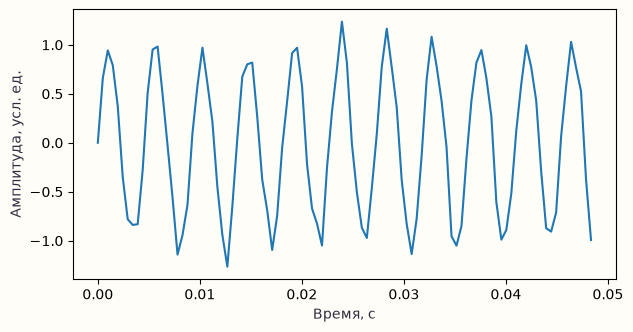

In [2]:
t = np.arange(fs * 2) / fs
labels = np.repeat([0, 1], 6)
frequencies = np.where(labels == 0, 220, 440)
recordings = np.array([
    np.sin(2 * np.pi * f * t) + rng.normal(0, 0.12, t.size)
    for f in frequencies
])
train_ids = np.array([0, 1, 2, 3, 6, 7, 8, 9])
test_ids = np.array([4, 5, 10, 11])
assert set(train_ids).isdisjoint(test_ids)
assert recordings.shape == (12, fs * 2)
plt.plot(t[:100], recordings[0, :100])
plt.xlabel('Время, с')
plt.ylabel('Амплитуда, усл. ед.')
plt.show()


**Что проверить:** Короткий фрагмент волны и 12 отдельных записей.

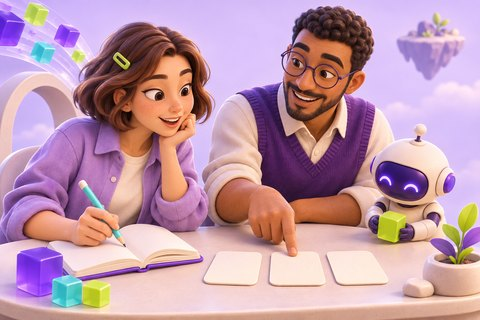

> **Мира:** Окна одной записи можно раздать в разные наборы?

> **Данил:** Нет: соседние окна почти повторяют друг друга. Разделяем целые записи.

> **Пикс:** Сравни train_ids и test_ids: пересечение должно быть пустым.

<a id="step-2"></a>

## 2. Преврати окна в два числа

Из каждой записи возьмём перекрывающиеся окна. Частота самого сильного тона и средняя энергия заменят длинную волну.

In [3]:
features, targets, groups = [], [], []
window = fs
for record_id, signal in enumerate(recordings):
    for start in range(0, len(signal) - window + 1, window // 2):
        part = signal[start:start + window]
        spectrum = np.abs(np.fft.rfft(part))
        peak = np.fft.rfftfreq(window, 1 / fs)[spectrum.argmax()]
        features.append([peak, np.sqrt(np.mean(part ** 2))])
        targets.append(labels[record_id])
        groups.append(record_id)
X, y, groups = np.array(features), np.array(targets), np.array(groups)
train = np.isin(groups, train_ids)
test = np.isin(groups, test_ids)
assert len(X) == 36 and not np.any(train & test)
assert set(groups[train]).isdisjoint(groups[test])
print('Окон: обучение', train.sum(), 'проверка', test.sum())


Окон: обучение 24 проверка 12


**Что проверить:** По три окна на запись; ни одна запись не попадает в оба набора.

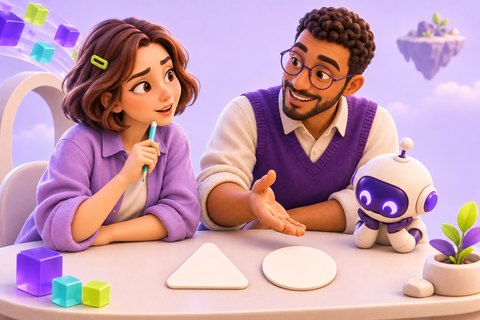

> **Мира:** Последнее окно заканчивается ровно в конце записи?

> **Данил:** Да. Поэтому верхняя граница range содержит +1: полное окно не теряется.

> **Пикс:** Проверь: 12 записей × 3 окна = 36.

<a id="step-3"></a>

## 3. Сравни с эталонами классов

Масштаб вычисляем только по обучающим окнам. Для каждого класса найдём центр и выберем ближайший к новому окну.

Доля верных ответов на искусственных сигналах: 1.00


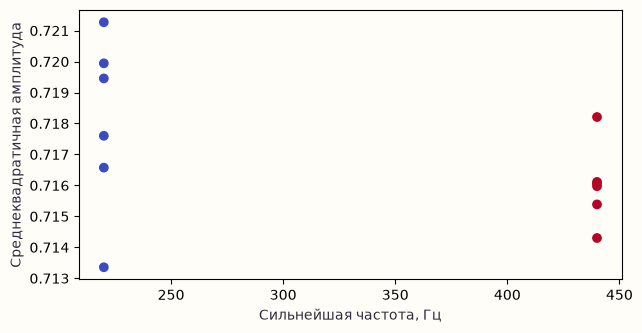

In [4]:
low = X[train].min(axis=0)
span = np.ptp(X[train], axis=0)
scale = np.where(span == 0, 1, span)
Z = (X - low) / scale
centers = np.array([Z[train & (y == cls)].mean(axis=0) for cls in [0, 1]])
distance = ((Z[test, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
predicted = distance.argmin(axis=1)
accuracy = np.mean(predicted == y[test])
assert np.isfinite(Z).all()
assert predicted.shape == y[test].shape
print(f'Доля верных ответов на искусственных сигналах: {accuracy:.2f}')
plt.scatter(X[test, 0], X[test, 1], c=predicted, cmap='coolwarm')
plt.xlabel('Сильнейшая частота, Гц')
plt.ylabel('Среднеквадратичная амплитуда')
plt.show()


**Что проверить:** Две группы тестовых окон и вычисленная доля верных ответов.

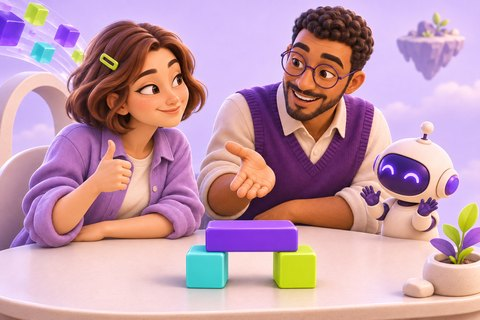

> **Мира:** Высокий результат уже означает, что мы узнаём птиц?

> **Данил:** Пока только два искусственных сигнала. Настоящие птицы звучат гораздо разнообразнее.

> **Пикс:** Меняй шум и наблюдай результат; не подбирай параметры по финальному тесту.

<a id="your-experiment"></a>

## Попробуй сам

Увеличь шум с 0.12 до 0.8.

**Где изменить:** Генерация recordings в первом шаге.

**Как проверить:** Размеры и разделение сохраняются; сравни вычисленную долю ответов.

## Что теперь умеешь

- Разделяй исходные записи, а не похожие окна.
- Параметры нормировки считаются на обучении.

## Границы этого примера

- Нет реальных птиц, обученной нейросети или микрофона.

## Продолжить глубже

[Полная исходная работа в неизменяемом архиве](<https://github.com/safal207/students/blob/2e46691c24aabcb6e71852e07254a0965fc3a59b/AudioNet/%D0%A1%D0%B0%D1%84%D0%BE%D0%BD%D0%BE%D0%B2%22%D0%90%D1%83%D0%B4%D0%B8%D0%BE_%D0%A0%D0%B0%D1%81%D0%BF%D0%BE%D0%B7%D0%BD%D0%B0%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5_%D0%BF%D1%82%D0%B8%D1%86_%D0%BF%D0%BE_%D0%BF%D0%B5%D0%BD%D0%B8%D1%8E_ipynb%22.ipynb>). Она сохраняет большой эксперимент и его авторские материалы; её требования могут отличаться от этого короткого урока.

**Источники исходной работы:**

- [Источник 1](<https://colab.research.google.com/github/safal207/hello-world/blob/master/%D0%A1%D0%B0%D1%84%D0%BE%D0%BD%D0%BE%D0%B2%22%D0%90%D1%83%D0%B4%D0%B8%D0%BE_%D0%A0%D0%B0%D1%81%D0%BF%D0%BE%D0%B7%D0%BD%D0%B0%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5_%D0%BF%D1%82%D0%B8%D1%86_%D0%BF%D0%BE_%D0%BF%D0%B5%D0%BD%D0%B8%D1%8E_ipynb%22.ipynb>)

<details>
<summary>Что исправлено и упрощено в уроке</summary>

**Ошибка · исходная ячейка 22 (от 0).** Соседние окна одной записи могут попасть в разные наборы. → Разделение по идентификаторам записей до выбора окон.

Проверка: Множества groups[train] и groups[test] не пересекаются.

Фрагмент исходника: <code>mask=np.random.sample(16540)</code>

---

**Ошибка · исходная ячейка 20 (от 0).** Масштаб рассчитан на всех данных до разделения. → min и ptp вычисляются только по train.

Проверка: Z конечен; нулевой диапазон заменяется единицей.

Фрагмент исходника: <code>Нормировка всех X предшествует ячейке22.</code>

---

**Ошибка · исходная ячейка 12 (от 0).** Последнее полное окно исключалось. → Границы окон вычисляются по длине массива с включением последнего.

Проверка: 36 окон для 12 записей по 2 секунды.

Фрагмент исходника: <code>range(0, int(len(y)//22050)-4)</code>

</details>